# Expirement running multiple ASP programs multiple times to get mean grounding/solving times

### Loading puzzles

In [2]:
import clingo
import time
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib.pyplot as plt
from pathlib import Path
import time
from concurrent.futures import ThreadPoolExecutor
import sys
import importlib

def load_program(puzzle, gen, configuration, base_rules, puzzle_path):
    '''
        Load the necessary lp files to load a complete puzzle:
        - with base file
        - with puzzle world
        - with clues
        and create a clingo control variable
    '''
    ctl = clingo.Control(["0", "--stats=2", "--warn=no-atom-undefined", f"--configuration={configuration}"])
    ctl.load('../solve-experiment.lp')
    ctl.load(f'../{base_rules}')
    if gen:
        ctl.load(f'../autogenerated_puzzles/puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../autogenerated_puzzles/clues/clues{puzzle}.lp')
    else:
        ctl.load(f'{puzzle_path}/puzzle{puzzle}.lp')
        ctl.load(f'../clues/clues{puzzle}.lp')
    ground_start = time.perf_counter()
    ctl.ground([("base", [])])
    ground_time = time.perf_counter() - ground_start
    grounded_at = sum(1 for atom in ctl.symbolic_atoms.by_signature('at', 3)) # grounded placements for people at certain locations
    return ctl, ground_time, grounded_at
 
def solve_puzzle(puzzle, gen=False, count=False, configuration='auto', base_rules='base-rules.lp', debug=False, puzzle_path='../puzzles'):
    '''
        Solve a clingo program by loading an lp file.
        Output atoms
        Output all solutions
    '''
    ctl, ground_time, grounded_at = load_program(puzzle, gen, configuration, base_rules, puzzle_path)
    def on_model(model):
        if debug:
            print(model.symbols(shown=True))
        else:
            pass
    with ctl.solve(on_model=on_model, yield_=True) as handle:
        models = list(handle)
        result = handle.get()
        stats = ctl.statistics
        solve_time = stats['summary']['times']['solve']
        grid_size = ctl.get_const('n').number

        # extract number of clues:
        atoms = ctl.symbolic_atoms
        clue_count = sum(1 for atom in atoms if atom.symbol.name == 'clue')

        #extract the types of clues:
        all_clue_types = ['in_same_room', 'not_in_same_room', 'next_to', 'not_next_to', 'on', 'in', \
                    'in_top_row', 'in_bottom_row', 'in_left_column', 'in_right_column', 'alone', 'not_alone', 'not_in',  'in_corner', 'not_in_corner', 'no_empty_room', \
                    'in_room_with_female', 'not_in_room_with_female', 'in_room_with_male', 'not_in_room_with_male', 'not_on', 'only_one_on',  'n_persons_on', 'in_room_with_multiple_females', 'in_room_with_multiple_males', \
                    'east_of', 'west_of', 'north_of', 'south_of', 'next_to_with_someone_else', 'object_in_col', 'no_object_in_col', 'object_in_row', 'no_object_in_row', \
                    'in_column', 'in_row', 'n_east_of', 'n_west_of', 'n_north_of', 'n_south_of', 'someone_else_in_room_on', 'someone_else_in_room_next_to', 'object_in_same_room']
        clue_type_counts = {}
        for atom in atoms:
            if atom.symbol.name == 'clue':
                args = [str(arg) for arg in atom.symbol.arguments]
                for arg in args:
                    if arg in all_clue_types:
                        clue_type_counts[arg] = clue_type_counts.setdefault(arg, 0) + 1

    if count:
        print(f'Number of models: {len(models)}')
        
    if debug:
        print(result)
        print("Satisfiable:", result.satisfiable)
        print("Unsatisfiable:", result.unsatisfiable)
        print("Unknown:", result.unknown)
    return result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at

#### Store results

In [513]:
def store_result(results, epoch, puzzle, type, ground_time, solve_time, total_time, grid_size, clue_count, clue_type_counts, solve_state, num_solutions, choice_type, grounded_at, constraint_type):
    results.append({
        'epoch': epoch, # epoch
        'puzzle': puzzle, # puzzle number
        'type': type, # automated puzzles with 'type': 'A' manual with 'M', comes from file names.
        'ground_time': ground_time, # time spent on grounding all possibilities
        'solve_time': solve_time, # time spent on solving all grounded rules
        'total_time': total_time, # total time
        'grid_size': grid_size, # grid size of puzzle X*X
        'clue_count': clue_count, # number of clues
        'clue_type_counts': clue_type_counts, # dictionary with types of clues
        'solve_state': solve_state, # is puzzle satisfiable
        'num_solutions': num_solutions, # number of solutions, should always be 1
        'choice_type': choice_type, # normal
        'grounded_at': grounded_at, # add number of grounded at/3 predicates
        'constraint_type': constraint_type # type of constraint for unique row and col
    })

#### Small experiment with dynamic choice rules vs normal choice rules
```ASP
# const n=6.
suspect(1, alphonse).
suspect(2, bonnie).
suspect(3, carol).
suspect(4, daniel).
suspect(5,emily).
victim(6,victor).

row(R) :- R = 0..n.
col(C) :- C = 0..n. 
step(T) :- T = 1..n+1.

{assign(P,R,C,T) : row(R), col(C), not occupied_row(R,T), not occupied_col(C,T), can_occupy(R,C)} = 1 :- person(T,P).

occupied_row(R,T) :- step(T), assign(_,R,_,T0), T0 < T.
occupied_col(C,T) :- step(T), assign(_,_,C,T0), T0 < T.

at(P,R,C) :- assign(P,R,C,T).
```

#### Small experiment between normal constraints and aggregate constraints
```ASP
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), R1=R2, P1!=P2.
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), C1=C2, P1!=P2.
```

VS

```ASP
:- at(_,_,C), #count{P : at(P,R,C)} != 1.
:- at(_,R,_), #count{P : at(P,R,C)} != 1.
```

In [592]:
epochs=5
puzzles = list(Path('../puzzles_dynamic').glob("puzzle*.lp"))
results_choice_agg = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, clue_type_counts_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-dyn.lp', puzzle_path='../puzzles_dynamic')
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, clue_type_counts_agg, models_agg, grounded_at_agg = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        store_result(results_choice_agg, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'ASP', grounded_at, 'Normal')
        store_result(results_choice_agg, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, clue_type_counts_dyn, result_dyn.satisfiable, len(models_dyn), 'Dynamic Choice', grounded_at_dyn, 'Normal')
        store_result(results_choice_agg, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size_agg + 1, clue_count_agg, clue_type_counts_agg, result_agg.satisfiable, len(models_agg), 'Agg Constraint', grounded_at_agg, 'Aggregate')
    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 1/5

----------------------------------

start epoch 2/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 2/5

----------------------------------

start epoch 3/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 3/5

----------------------------------

start epoch 4/5


In [593]:
# put results in pandas frame
df_choice_agg= pd.DataFrame(results_choice_agg)
df_choice_agg.head()

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.183946,0.039129,0.223075,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549,Normal
1,0,30,M,0.136495,0.042455,0.178950,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Dynamic Choice,549,Normal
2,0,30,M,0.134334,0.016610,0.150944,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Agg Constraint,549,Aggregate
3,0,55,M,0.154731,0.095581,0.250312,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540,Normal
4,0,55,M,0.148079,0.170095,0.318173,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,Dynamic Choice,540,Normal


In [594]:
# check for failed solutions or multiple solutions
failed = df_choice_agg[df_choice_agg['solve_state'] == False]
len(failed)

0

In [595]:
# check for failed solutions or multiple (or no) solutions
wrong_sol = df_choice_agg[df_choice_agg['num_solutions'] != 1]
len(wrong_sol)

0

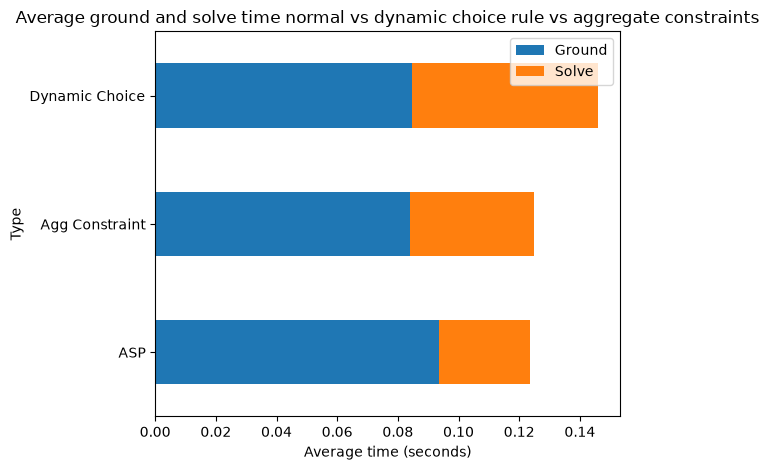

In [596]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice_agg.groupby('choice_type')[['ground_time','solve_time']].mean().plot(kind='barh', stacked=True)

plt.title('Average ground and solve time normal vs dynamic choice rule vs aggregate constraints')
plt.ylabel('Type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'])
plt.tight_layout()
plt.show()

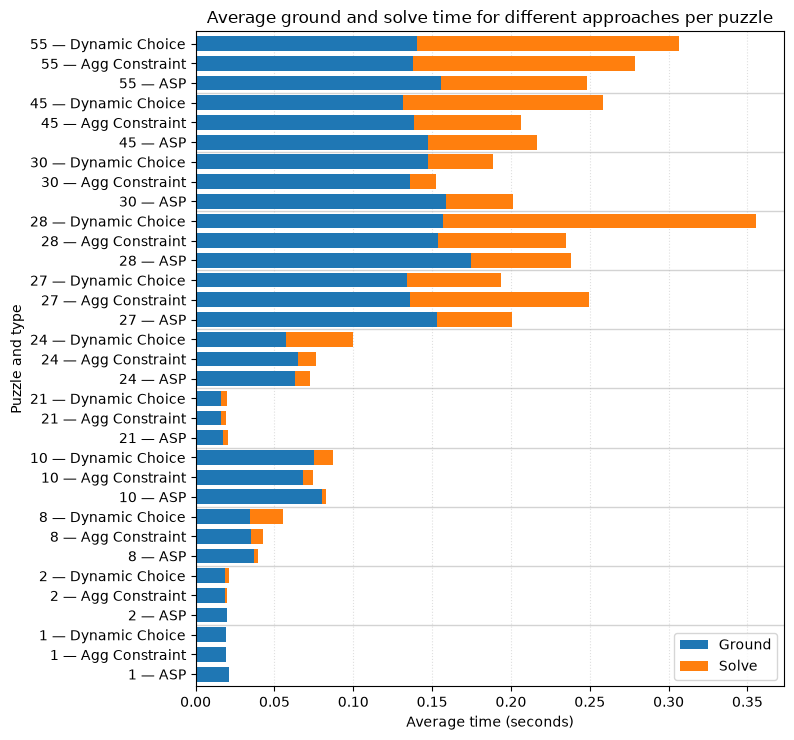

In [603]:
# compare number of ground predicates for at/3 in resulting grounded program
df_plot = (
    df_choice_agg
    .groupby(['puzzle', 'choice_type'])[['ground_time', 'solve_time']]
    .mean()
    .sort_index()
)

ax = df_plot.plot(kind='barh', stacked=True, width=0.75, figsize=(8, 7.5))

plt.title('Average ground and solve time for different approaches per puzzle')
plt.ylabel('Puzzle and type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'], loc='lower right')
plt.tight_layout()

# Draw separators after every three bars
n_results = 3
for y in np.arange(n_results - 0.5, len(df_plot) - 0.5, n_results):
    ax.axhline(y=y, color='lightgray', linewidth=1, zorder=0)

ax.set_yticks(
    np.arange(len(df_plot)),
    [f'{puzzle} — {choice_type}' for puzzle, choice_type in df_plot.index]
)

# Keep gridlines behind the bars
ax.set_axisbelow(True)
ax.xaxis.grid(True, linestyle=':', alpha=0.4)

plt.show()

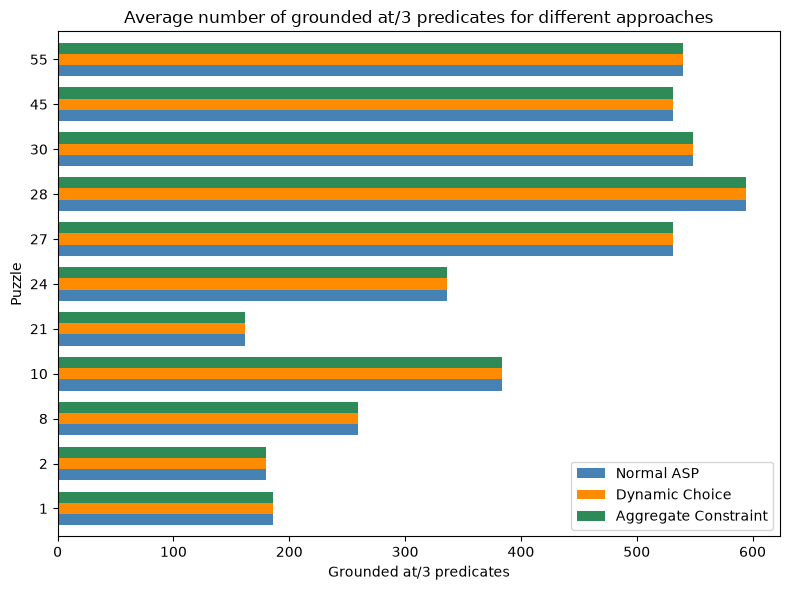

In [604]:
# compare ground_time/solve_time/total_time for both approaches
df_choice_agg.groupby(['puzzle','choice_type'])[['grounded_at']].mean().unstack('choice_type').plot(
    kind='barh', color=['steelblue', 'darkorange', 'seagreen'], width=0.75, figsize=(8,6)
)

plt.title('Average number of grounded at/3 predicates for different approaches')
plt.ylabel('Puzzle')
plt.xlabel('Grounded at/3 predicates')
plt.legend(['Normal ASP', 'Dynamic Choice', 'Aggregate Constraint'])
plt.tight_layout()
plt.show()

## Run main experiment
- epoch is one run of all available puzzles
- type 'M' puzzles are manually taken from Murdoku book 1
- type 'A' puzzles are automatically generated with our Murdoku-generator
- statistics like grounding time, solving time, total time, grid size and number of clues are stored per puzzle per epoch, these can later be used for analysis
- Python vs ASP vs ASP with aggregate constraints


In [515]:
# Reload the module after it has been updated
project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root))

import solver.pythonsolver as pythonsolver


importlib.reload(pythonsolver)


<module 'solver.pythonsolver' from '/Users/jurgen/Code/MASTER_OU/MBAI/project/murdoku-solve/solver/pythonsolver.py'>

### Original run (non parallel).
For parallel solving (3 approaches per puzzle), see below

In [ ]:
# number of runs for experiment
epochs = 3
debug = False

puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results = []
for i in range(epochs):
    if debug:
        print(f'start epoch {i+1}/{epochs}')

    for ip, p in enumerate(puzzles):
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        grid_size_from_file_name = int(puzzle_id.split('-')[0][1:])
        if debug:
            print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')

        # run both ASP implementations
        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, clue_type_counts_agg, models_agg, grounded_at_agg = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        # run python solver:                
        puzzle_base_path = '..' if puzzle_type == 'M' else '../autogenerated_puzzles'
        pfile = f'{puzzle_base_path}/puzzles/puzzle{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        cfile = f'{puzzle_base_path}/clues/clues{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        n_sol_python, interpret_time_python, solve_time_python, solutions_python, n_clues_python, clue_type_counts_python = pythonsolver.find_solutions(pfile, cfile)

        # store results for 3 methods:
        store_result(results, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'ASP', grounded_at, 'Normal')
        store_result(results, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size + 1, clue_count, clue_type_counts_agg, result_agg.satisfiable, len(models_agg), 'ASP', grounded_at_agg, 'Aggregate')
        store_result(results, i, puzzle_num, puzzle_type, interpret_time_python, solve_time_python, interpret_time_python + solve_time_python, grid_size_from_file_name, n_clues_python, clue_type_counts_python, n_sol_python>0, n_sol_python, 'Python', None, 'Python')

        if ip > 0 and ip % 50 == 0:
            print(f'epoch {i+1}/{epochs} at {ip}/{len(puzzles)} puzzles')

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/1
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
Puzzle #A6-69, A, True
Puzzle #A13-58, A, True
Puzzle #A7-94, A, True
Puzzle #A5-80, A, True
Puzzle #A9-97, A, True
Puzzle #A6-38, A, True
Puzzle #A9-64, A, True
Puzzle #A10-42, A, True
Puzzle #A8-99, A, True
Puzzle #A5-73, A, True
Puzzle #A7-36, A, True
Puzzle #A10-13, A, True
Puzzle #A9-35, A, True
Puzzle #A5-22, A, True
Puzzle #A7-67, A, True
Puzzle #A12-56, A, True
Puzzle #A10-9, A, True
Puzzle #A11-78, A, True
Puzzle #A4-49, A, True
Puzzle #A10-85, A, True
Puzzle #A12-91, A, True
Puzzle #A11-29, A, True
Puzzle #A4-18, A, True
Puzzle #A7-53, A, True
Puzzle #A12-62, A, True
Puzzle #A6-8, A, True
Puzzle #A10-27, A, True
Puzzle #A5-16, A, True
Puzzle #A12-33, A, True
Puzzle #A10-76, A, True
Puzzle #A9-50, A, True

KeyboardInterrupt: 

### Parallel uitvoeren van verschillende methodes per puzzle

In [516]:
def run_task(task):
    puzzle_id, puzzle_type, grid_size, approach = task

    if approach == "ASP":
        return solve_puzzle(
            puzzle_id,
            puzzle_type == 'A',
            configuration='auto',
            base_rules='base-rules.lp'
        )

    elif approach == "AGG":
        return solve_puzzle(
            puzzle_id,
            puzzle_type == 'A',
            configuration='auto',
            base_rules='base-rules-agg.lp'
        )

    elif approach == "Python":
        puzzle_base_path = '..' if puzzle_type == 'M' else '../autogenerated_puzzles'
        pfile = f'{puzzle_base_path}/puzzles/puzzle{puzzle_type}{grid_size}-{puzzle_num}.lp'
        cfile = f'{puzzle_base_path}/clues/clues{puzzle_type}{grid_size}-{puzzle_num}.lp'
        return pythonsolver.find_solutions(pfile, cfile)

In [ ]:
epochs = 1
debug = False

puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results_par = []

executor = ThreadPoolExecutor(max_workers=3)

for i in range(epochs):
    start_epoch = time.perf_counter()
    start_batch = time.perf_counter()
    if debug:
        print(f'start epoch {i+1}/{epochs}')

    for ip, p in enumerate(puzzles):
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        grid_size_from_file_name = int(puzzle_id.split('-')[0][1:])

        # create tasks for parallel processing
        tasks = [
            (puzzle_id, puzzle_type, grid_size_from_file_name, 'ASP'),
            (puzzle_id, puzzle_type, grid_size_from_file_name, 'AGG'),
            (puzzle_id, puzzle_type, grid_size_from_file_name, 'Python')
        ]

        futures = [executor.submit(run_task, task) for task in tasks]
        result_set = [future.result() for future in futures]

        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = result_set[0]
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, clue_type_counts_agg, models_agg, grounded_at_agg = result_set[1]
        n_sol_python, interpret_time_python, solve_time_python, solutions_python, n_clues_python, clue_type_counts_python = result_set[2]

        # store results
        store_result(results_par, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'ASP', grounded_at, 'ASP')
        store_result(results_par, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size + 1, clue_count_agg, clue_type_counts_agg, result_agg.satisfiable, len(models_agg), 'ASP', grounded_at_agg, 'Aggregate constraints')
        store_result(results_par, i, puzzle_num, puzzle_type, interpret_time_python, solve_time_python, interpret_time_python + solve_time_python, grid_size_from_file_name, n_clues_python, clue_type_counts_python, n_sol_python>0, n_sol_python, 'Python', None, 'Python')

        if ip > 0 and ip % 50 == 0:
            elapsed_batch = time.perf_counter() - start_batch
            print(f'epoch {i+1}/{epochs} at {ip}/{len(puzzles)} puzzles')
            print(f"Elapsed batch time: {elapsed_batch:.2f} seconds")
            start_batch = time.perf_counter()

    elapsed_epoch = time.perf_counter() - start_epoch
    print(f'end epoch {i+1}/{epochs}')
    print(f"Elapsed epoch time: {elapsed_epoch:.2f} seconds")
    print()
    print('----------------------------------')
    print()
executor.shutdown()

epoch 1/1 at 50/1071 puzzles
Elapsed batch time: 423.35 seconds
epoch 1/1 at 100/1071 puzzles
Elapsed batch time: 176.44 seconds
epoch 1/1 at 150/1071 puzzles
Elapsed batch time: 325.04 seconds
epoch 1/1 at 200/1071 puzzles
Elapsed batch time: 278.93 seconds
epoch 1/1 at 250/1071 puzzles
Elapsed batch time: 169.14 seconds
epoch 1/1 at 300/1071 puzzles
Elapsed batch time: 256.18 seconds
epoch 1/1 at 350/1071 puzzles
Elapsed batch time: 226.48 seconds
epoch 1/1 at 400/1071 puzzles
Elapsed batch time: 280.28 seconds
epoch 1/1 at 450/1071 puzzles
Elapsed batch time: 275.79 seconds
epoch 1/1 at 500/1071 puzzles
Elapsed batch time: 151.35 seconds
epoch 1/1 at 550/1071 puzzles
Elapsed batch time: 228.65 seconds
epoch 1/1 at 600/1071 puzzles
Elapsed batch time: 156.89 seconds
epoch 1/1 at 650/1071 puzzles
Elapsed batch time: 267.06 seconds
epoch 1/1 at 700/1071 puzzles
Elapsed batch time: 241.94 seconds
epoch 1/1 at 750/1071 puzzles
Elapsed batch time: 176.91 seconds
epoch 1/1 at 800/1071 puzz

### Analyze
- convert results to Pandas DataFrame for easy evaluation

#### Error checks
- check for unsatisfiable puzzles
- check for puzzles with multiple solutions

#### Compare results
- Compare results between approaches
- Compare performance between puzzles (commented out)
- Compare performance between grid sizes
- Compare performance between number of clues
- Compare performance between generated and manual puzzles
- Compare performance between combination of grid size and number of clues
- Compare performance between combination of grid size and generated/manual

In [608]:
df = pd.DataFrame(results_par)
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 3213 entries, 0 to 3212
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   epoch             3213 non-null   int64  
 1   puzzle            3213 non-null   int64  
 2   type              3213 non-null   str    
 3   ground_time       3213 non-null   float64
 4   solve_time        3213 non-null   float64
 5   total_time        3213 non-null   float64
 6   grid_size         3213 non-null   int64  
 7   clue_count        3213 non-null   int64  
 8   clue_type_counts  3213 non-null   object 
 9   solve_state       3213 non-null   bool   
 10  num_solutions     3213 non-null   int64  
 11  choice_type       3213 non-null   str    
 12  grounded_at       2142 non-null   float64
 13  constraint_type   3213 non-null   str    
dtypes: bool(1), float64(4), int64(5), object(1), str(3)
memory usage: 329.6+ KB


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.207225,0.044823,0.252048,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549.0,Normal
1,0,30,M,0.188413,0.021773,0.210186,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,ASP,549.0,Aggregate
2,0,30,M,0.001015,0.006342,0.007357,9,10,"{'next_to': 3, 'alone': 1, 'in': 1, 'not_in': ...",True,1,Python,NaN,Python
3,0,55,M,0.170838,0.124284,0.295122,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540.0,Normal
4,0,55,M,0.156474,0.167576,0.324050,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,ASP,540.0,Aggregate


In [ ]:
df.to_csv('main-results-par-3.csv', index=False)

In [533]:
(~df['solve_state']).sum()

np.int64(0)

In [534]:
# check for puzzles with multiple solutions
multi_solutions = df[(df['num_solutions'] > 1) & (df['epoch'] == 0)]
multi_solutions

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type


In [535]:
# get average times per method
df.groupby('constraint_type')[['ground_time','solve_time','total_time']].mean()

,ground_time,solve_time,total_time
constraint_type,,,
Aggregate,0.703625,2.511428,3.215053
Normal,0.802189,2.491449,3.293638
Python,0.003129,1.102597,1.105726


constraint_type  Aggregate    Normal     Python
type                                           
A                 3.246769  3.326172   0.937400
M                 0.158786  0.158584  17.326235


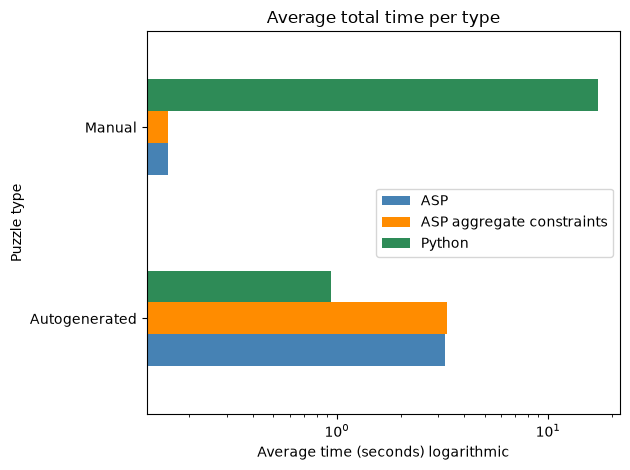

In [612]:
# average ground/solve/total times per method
df_grouped = df.groupby(['type', 'constraint_type'])['total_time'].mean().unstack('constraint_type')
print(df_grouped)
ax = df_grouped.plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

labels = {'M': 'Manual','A': 'Autogenerated'}

ax.set_xscale('log')
plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds) logarithmic')
plt.yticks(
    ticks=range(len(df_grouped.index)),
    labels=[labels[x] for x in df_grouped.index]
)
plt.title('Average total time per type')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'])
plt.tight_layout()
plt.show()

### Store results

In [537]:
df.to_csv('main-results.csv', index=False)

In [ ]:
# reload results
df = pd.read_csv('main-results.csv')

### Compare Python vs ASP vs ASP with aggregate constraint

In [538]:
print(len(df[df['constraint_type'] == 'Normal'][['puzzle','type','grid_size']]))
print(len(df[df['constraint_type'] == 'Python'][['puzzle','type','grid_size']]))
print(len(df[df['constraint_type'] == 'Aggregate'][['puzzle','type','grid_size']]))

1071
1071
1071


In [539]:
# get average times per method
df.groupby('constraint_type')[['ground_time','solve_time','total_time']].mean()

,ground_time,solve_time,total_time
constraint_type,,,
Aggregate,0.703625,2.511428,3.215053
Normal,0.802189,2.491449,3.293638
Python,0.003129,1.102597,1.105726


In [540]:
# Check whether each puzzle is solved once per epoch per method
df.groupby(['epoch','puzzle', 'type', 'grid_size', 'constraint_type']).size().sort_values(ascending=False)

epoch  puzzle  type  grid_size  constraint_type
0      1       A     4          Aggregate          1
       65      A     8          Normal             1
                     5          Aggregate          1
                                Normal             1
                                Python             1
                                                  ..
       32      A     12         Aggregate          1
                                Normal             1
                                Python             1
                     13         Aggregate          1
       100     A     13         Python             1
Length: 3213, dtype: int64

In [541]:
# get mean scores per puzzle per method and find longest total time
df.groupby(['puzzle', 'type', 'grid_size', 'constraint_type'])[
    ['ground_time', 'solve_time', 'total_time']
].mean().sort_values('total_time', ascending=False).head(30)

,,,,ground_time,solve_time,total_time
puzzle,type,grid_size,constraint_type,,,
28,M,9,Python,0.002835,186.287778,186.290613
34,A,14,Normal,3.982072,55.605876,59.587948
49,A,14,Normal,4.289775,48.269349,52.559124
41,A,14,Aggregate,3.407208,47.037290,50.444498
44,A,13,Aggregate,2.347859,48.052104,50.399963
12,A,14,Aggregate,3.712833,43.157269,46.870102
18,A,14,Normal,4.151625,42.173200,46.324825
52,A,13,Normal,2.640636,43.316492,45.957128
12,A,14,Normal,4.233581,40.416630,44.650211


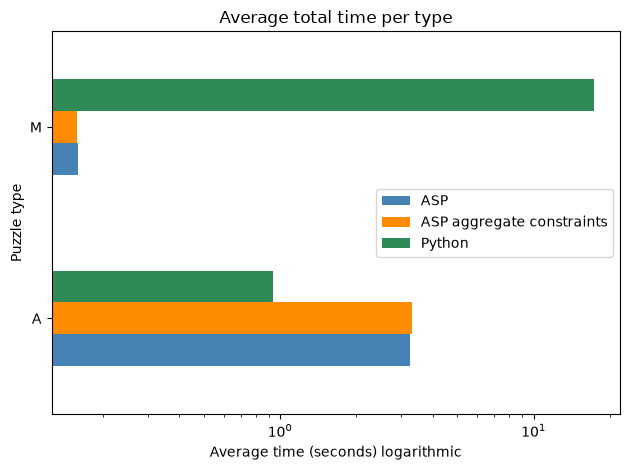

In [542]:
# average ground/solve/total times per method
ax = df.groupby(['type', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

ax.set_xscale('log')
plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds) logarithmic')
plt.title('Average total time per type')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'])
plt.tight_layout()
plt.show()

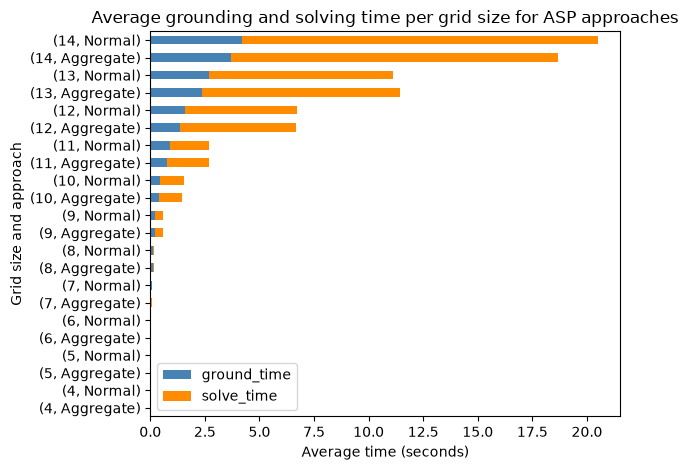

In [602]:
# Compare average ground/solve times ASP per grid size
df_asp = df[df['constraint_type'] != 'Python']

ax = df_asp.groupby(['grid_size', 'constraint_type'])[
    ['ground_time', 'solve_time']
].mean().plot(
    kind='barh',
    stacked=True,
    color=['steelblue', 'darkorange']
)

plt.ylabel('Grid size and approach')
plt.xlabel('Average time (seconds)')
plt.title('Average grounding and solving time per grid size for ASP approaches')
plt.tight_layout()
plt.show()

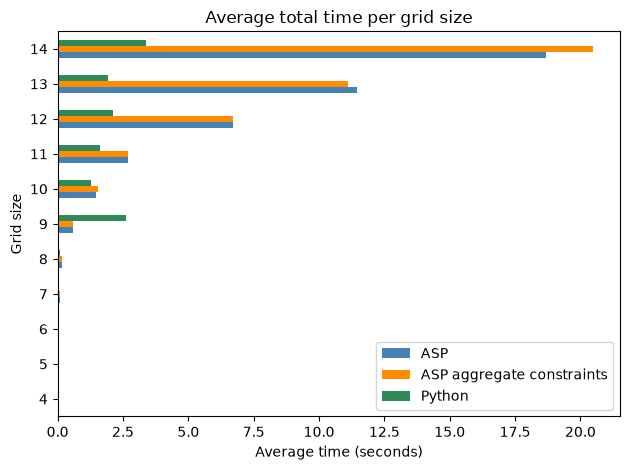

In [543]:
# Compare average total time spend per grid size between methods
ax = df.groupby(['grid_size', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Grid size')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per grid size')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

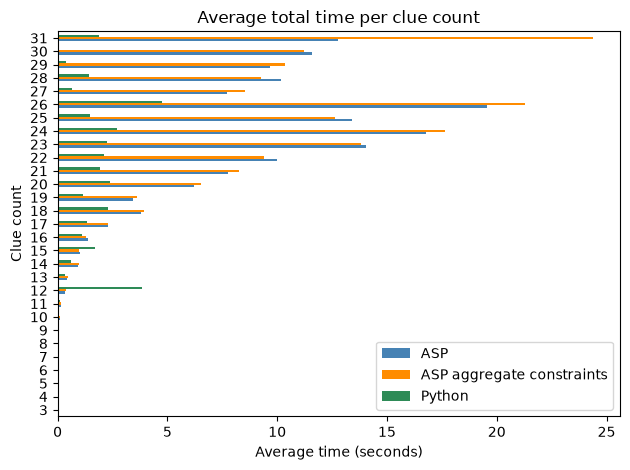

In [544]:
# Compare average total time spend per clue size between methods
ax = df.groupby(['clue_count', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per clue count')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

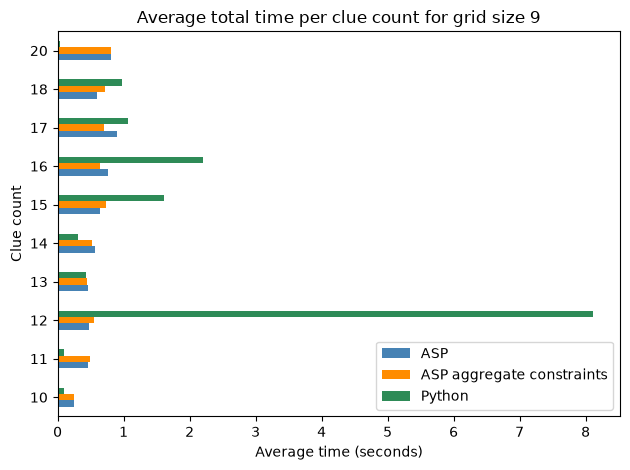

In [545]:
# One interesting combination seems to be clue count = 12 and grid size = 9
# Compare average total time spend per clue size for grid size = 9 between methods
df_grid_size_9 = df[df['grid_size'] == 9]

ax = df_grid_size_9.groupby(['clue_count', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per clue count for grid size 9')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

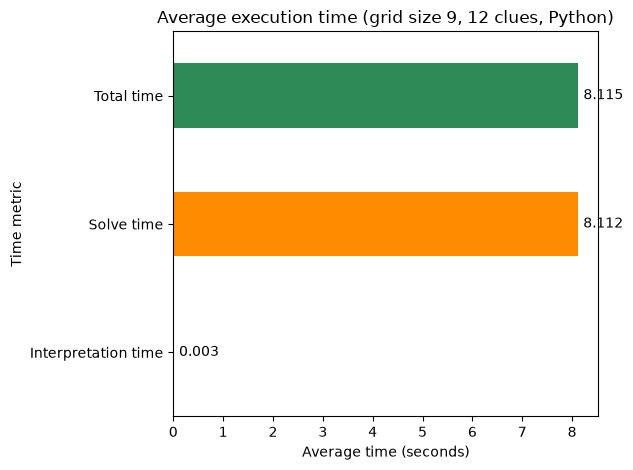

In [554]:
# One interesting combination seems to be clue count = 12 and grid size = 9
# Compare average ground/solve/total time spend
df_grid_size_9_clue_size_12_python = df[(df['grid_size'] == 9) & (df['clue_count'] == 12) & (df['constraint_type'] == 'Python')]

times = df_grid_size_9_clue_size_12_python[['ground_time','solve_time','total_time']].mean()
times.index = ['Interpretation time', 'Solve time', 'Total time']

ax = times.plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)
ax.bar_label(ax.containers[0], fmt='%.3f', padding=4)

ax.set_ylabel('Time metric')
ax.set_xlabel('Average time (seconds)')
ax.set_title('Average execution time (grid size 9, 12 clues, Python)')
plt.tight_layout()
plt.show()

In [547]:
# Must be solving time then, it is because of Manual input puzzle 28 which has 90 seconds of solving time. Inspect?
df_grid_size_9_clue_size_12_python.head(100) 

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
8,0,45,M,0.004795,4.028840,4.033635,9,12,"{'in': 1, 'east_of': 1, 'south_of': 1, 'next_t...",True,1,Python,NaN,Python
26,0,28,M,0.002835,186.287778,186.290613,9,12,"{'only_one_on': 1, 'someone_else_in_room_next_...",True,1,Python,NaN,Python
71,0,35,A,0.004774,0.060087,0.064861,9,12,"{'n_persons_on': 1, 'someone_else_in_room_next...",True,1,Python,NaN,Python
125,0,50,A,0.005114,0.110682,0.115796,9,12,"{'only_one_on': 1, 'in': 2, 'not_alone': 1, 'i...",True,1,Python,NaN,Python
149,0,40,A,0.003972,0.018288,0.022260,9,12,"{'in_same_room': 1, 'not_next_to': 2, 'no_obje...",True,1,Python,NaN,Python
170,0,11,A,0.005168,0.001036,0.006204,9,12,"{'not_next_to': 1, 'alone': 2, 'on': 2, 'in': ...",True,1,Python,NaN,Python
269,0,54,A,0.004970,0.003651,0.008621,9,12,"{'on': 2, 'n_east_of': 2, 'in_right_column': 1...",True,1,Python,NaN,Python
407,0,15,A,0.000516,0.165153,0.165669,9,12,"{'n_persons_on': 1, 'in_same_room': 1, 'n_east...",True,1,Python,NaN,Python
530,0,61,A,0.000626,0.005437,0.006063,9,12,"{'n_persons_on': 2, 'not_next_to': 1, 'next_to...",True,1,Python,NaN,Python
821,0,24,A,0.004593,0.000413,0.005006,9,12,"{'in': 1, 'in_left_column': 1, 'not_in_corner'...",True,1,Python,NaN,Python


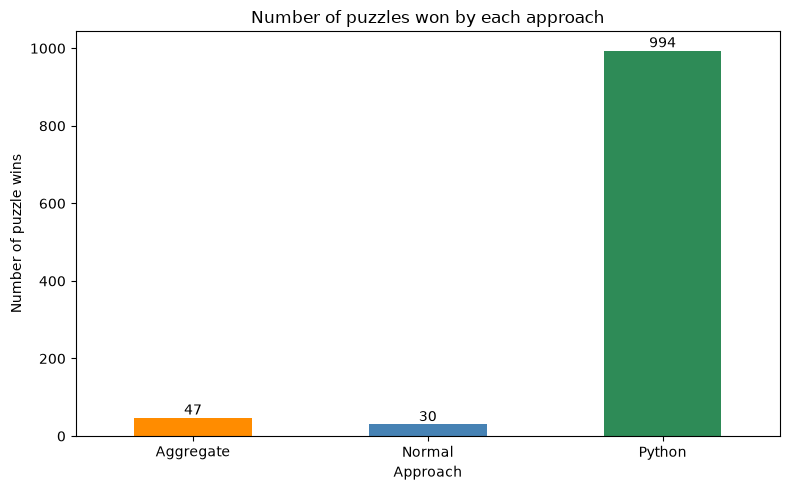

In [548]:
# Compare winner based on total time spent per puzzle averages
avg_total_times = df.groupby(['puzzle','type','grid_size','constraint_type'])['total_time'].mean().unstack('constraint_type')
winners = avg_total_times.idxmin(axis=1)
win_counts = winners.value_counts().reindex(avg_total_times.columns, fill_value=0)

colors = {
    'Normal': 'steelblue',
    'Aggregate': 'darkorange',
    'Python': 'seagreen'
}

ax = win_counts.plot(
    kind='bar',
    color=[colors[t] for t in win_counts.index],
    figsize=(8, 5)
)

ax.set_xlabel('Approach')
ax.set_ylabel('Number of puzzle wins')
ax.set_title('Number of puzzles won by each approach')
ax.bar_label(ax.containers[0], fmt='%d')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

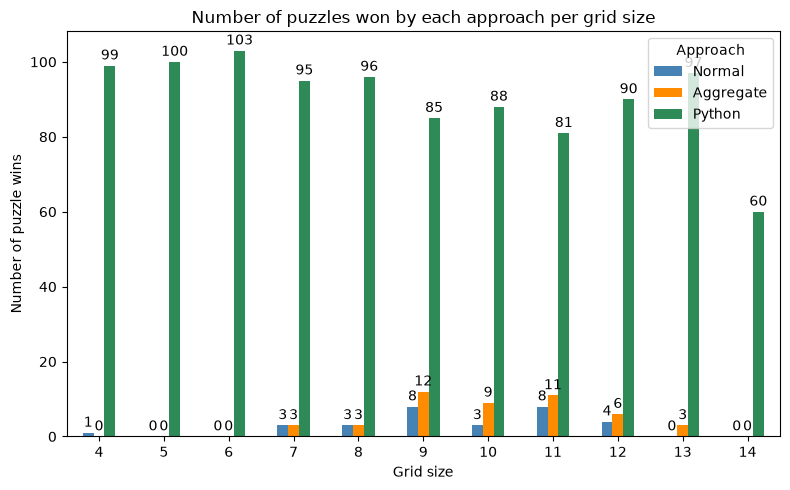

In [ ]:
# Compare winner based on total time spent per puzzle averages (divided per grid?)
avg_total_times = df.groupby(['puzzle','type','grid_size','constraint_type'])['total_time'].mean().unstack('constraint_type')
winners = avg_total_times.idxmin(axis=1).rename('winner')
winner_df = winners.reset_index()

win_counts = (
    winner_df.groupby(['grid_size', 'winner']).size().unstack('winner', fill_value=0)
)

approaches = ['Normal', 'Aggregate', 'Python']
win_counts = win_counts.reindex(columns=approaches, fill_value=0)

colors = {
    'Normal': 'steelblue',
    'Aggregate': 'darkorange',
    'Python': 'seagreen'
}

ax = win_counts.plot(
    kind='bar',
    color=[colors[t] for t in win_counts.columns],
    figsize=(8, 5)
)

ax.set_xlabel('Grid size')
ax.set_ylabel('Number of puzzle wins')
ax.set_title('Number of puzzles won by each approach per grid size')
ax.bar_label(ax.containers[0], fmt='%d', padding=2)
ax.bar_label(ax.containers[1], fmt='%d', padding=2)
ax.bar_label(ax.containers[2], fmt='%d', padding=2)
plt.xticks(rotation=0)
plt.legend(title='Approach')
plt.tight_layout()
plt.show()

In [241]:
df.groupby('grid_size')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
grid_size,,,
4,0.003783,0.000329,0.004112
5,0.009235,0.001381,0.010616
6,0.021491,0.003923,0.025414
7,0.046995,0.014286,0.061282
8,0.096156,0.051067,0.147223
9,0.191893,0.135699,0.327592
10,0.361391,0.591928,0.953319
11,0.645106,2.302929,2.948034


In [33]:
#linear regression on the most important variables
#results = pd.DataFrame(results_choice)

dependent_variables = ['ground_time', 'solve_time']
independent_variables = ['grid_size', 'clue_count', 'grounded_at']
independent_variables_to_dummies = ['type', 'choice_type', 'constraint_type']

clue_generalization_dict = {
            'in_top_row': 'specific row/column',\
            'in_bottom_row': 'specific row/column',\
            'in_left_column': 'specific row/column',\
            'in_right_column': 'specific row/column',\
            'in_column': 'specific row/column',\
            'in_row': 'specific row/column',\

            'in_room_with_multiple_females': 'in room with multiple males/females',\
            'in_room_with_multiple_males': 'in room with multiple males/females',\

            'in_room_with_female': 'in room with male/female',\
            'in_room_with_male': 'in room with male/female',\

            'not_in_room_with_female': 'not in room with male/female',\
            'not_in_room_with_male': 'not in room with male/female',\

            'east_of': 'nesw of',\
            'west_of': 'nesw of',\
            'north_of': 'nesw of',\
            'south_of': 'nesw of',\

            'n_east_of': 'n nesw of',\
            'n_west_of': 'n nesw of',\
            'n_north_of': 'n nesw of',\
            'n_south_of': 'n nesw of',\

            'object_in_col': 'object in row/column',\
            'object_in_row': 'object in row/column',\

            'no_object_in_col': 'no object in row/column',\
            'no_object_in_row': 'no object in row/column'}

clue_counts_all = pd.json_normalize(results['clue_type_counts']).set_index(results.index)
sum_mapping = {}
for old_col, new_col in clue_generalization_dict.items():
    sum_mapping.setdefault(new_col, []).append(old_col)

for new_col, columns_to_combine in sum_mapping.items():
    valid_cols = [c for c in columns_to_combine if c in clue_counts_all.columns]
    if valid_cols:
        clue_counts_all[new_col] = clue_counts_all[valid_cols].sum(axis=1, min_count=1)

clue_counts_all = clue_counts_all.drop(columns=[key for key in clue_generalization_dict.keys()], errors='ignore')
clue_counts_all = clue_counts_all.fillna(0)

results_dummies = pd.get_dummies(results[independent_variables_to_dummies], drop_first=True, dtype=int)

results_indep = results[independent_variables].copy()
results_indep['number_of_cells'] = results_indep['grid_size'] ** 2

results_for_linreg = pd.concat([results_indep, results_dummies, clue_counts_all, results[dependent_variables]], axis=1)

In [ ]:
results_for_linreg.columns

Index(['grid_size', 'clue_count', 'grounded_at', 'number_of_cells', 'type_M',
       'choice_type_Python', 'constraint_type_Normal',
       'constraint_type_Python', 'next_to', 'in', 'not_in', 'only_one_on',
       'on', 'alone', 'in_corner', 'in_same_room', 'n_persons_on',
       'next_to_with_someone_else', 'no_empty_room', 'not_next_to',
       'someone_else_in_room_on', 'someone_else_in_room_next_to',
       'object_in_same_room', 'not_on', 'not_in_corner', 'not_in_same_room',
       'not_alone', 'specific row/column',
       'in room with multiple males/females', 'in room with male/female',
       'not in room with male/female', 'nesw of', 'n nesw of',
       'object in row/column', 'no object in row/column', 'ground_time',
       'solve_time'],
      dtype='str')

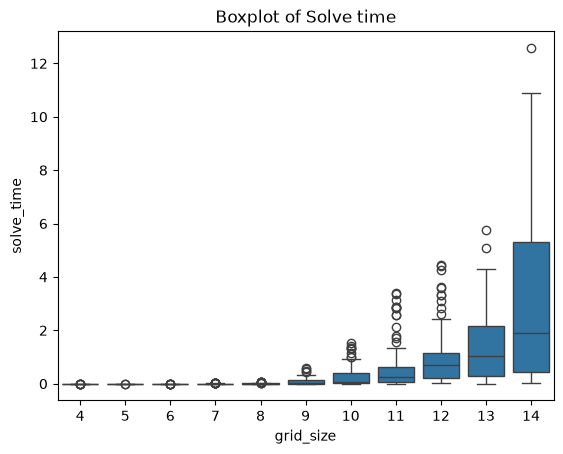

Root Mean Squared Error (RMSE): 1.19
R-squared: 0.89

                                 Feature   Coefficient
0                             grid_size  4.032292e+00
1                    choice_type_Python  8.326673e-16
2                constraint_type_Normal -1.221245e-15
3                constraint_type_Python -3.330669e-16
4                               next_to -6.113005e-01
5                                    in -6.327642e-01
6                                not_in  5.198144e-02
7                           only_one_on  2.074024e-01
8                                    on -4.233698e-01
9                                 alone  1.127443e-01
10                            in_corner -1.436110e-01
11                         n_persons_on  2.442919e-01
12            next_to_with_someone_else  1.611245e-01
13                        no_empty_room  2.897058e-02
14                          not_next_to  2.748394e-02
15                         in_same_room  2.479827e-01
16                  object_

In [87]:
from sklearn.preprocessing import PolynomialFeatures


#Actual regression
results_filter = (results_for_linreg['choice_type_Python'] == 1) #& (results_for_linreg['grid_size'] == 10)
results_for_linreg_subset = results_for_linreg[results_filter]

dep_value = 'solve_time'


def outlier_mask(x):
    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return (x >= lower) & (x <= upper)

valid_rows_mask = results_for_linreg_subset.groupby('grid_size')[dep_value].transform(outlier_mask)
results_for_linreg_subset = results_for_linreg_subset[valid_rows_mask].reset_index(drop=True)

import seaborn as sns
sns.boxplot(y='solve_time', x='grid_size', data = results_for_linreg_subset)
plt.title('Boxplot of Solve time')
plt.show()

y = np.log(results_for_linreg_subset[dep_value])

X = results_for_linreg_subset[['grid_size',#'clue_count',
       #'number_of_cells', 'type_M',
       'choice_type_Python', 'constraint_type_Normal',
       'constraint_type_Python', 'next_to',
       'in', 'not_in', 'only_one_on', 'on', 'alone', 'in_corner',
       'n_persons_on', 'next_to_with_someone_else', 'no_empty_room',
       'not_next_to', 'in_same_room', 'object_in_same_room', 'not_on',
       'someone_else_in_room_on', 'someone_else_in_room_next_to',
       'specific row/column', 'in room with multiple males/females',
       'in room with male/female', 'nesw of', 'n nesw of', 'no object in row/column']]



X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.2f}")

coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
print("\n", coefficients)

In [85]:
results_for_linreg_subset.describe()

,grid_size,clue_count,grounded_at,number_of_cells,type_M,choice_type_Python,constraint_type_Normal,constraint_type_Python,next_to,in,...,specific row/column,in room with multiple males/females,in room with male/female,not in room with male/female,nesw of,n nesw of,object in row/column,no object in row/column,ground_time,solve_time
count,88.0,88.000000,0.0,88.0,88.0,88.0,88.0,88.0,88.000000,88.000000,...,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000
mean,10.0,16.090909,NaN,100.0,0.0,1.0,0.0,1.0,2.363636,1.750000,...,1.568182,0.090909,0.159091,0.329545,0.886364,1.568182,0.488636,0.454545,0.002814,0.276397
std,0.0,1.921663,NaN,0.0,0.0,0.0,0.0,0.0,1.205179,1.085431,...,0.968414,0.289127,0.425788,0.601179,0.902510,1.122348,0.677967,0.659312,0.001314,0.386690
min,10.0,11.000000,NaN,100.0,0.0,1.0,0.0,1.0,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000491,0.002936
25%,10.0,15.000000,NaN,100.0,0.0,1.0,0.0,1.0,2.000000,1.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.002782,0.019040
50%,10.0,16.000000,NaN,100.0,0.0,1.0,0.0,1.0,2.000000,2.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.002934,0.071897
75%,10.0,17.000000,NaN,100.0,0.0,1.0,0.0,1.0,3.000000,2.000000,...,2.000000,0.000000,0.000000,1.000000,1.000000,2.000000,1.000000,1.000000,0.003418,0.399155
max,10.0,22.000000,NaN,100.0,0.0,1.0,0.0,1.0,6.000000,4.000000,...,4.000000,1.000000,2.000000,3.000000,3.000000,5.000000,4.000000,2.000000,0.005117,1.515296
